# 01 · Data cleaning & exploratory analysis

**Data:** every transaction of a UK online gift retailer, Dec 2009 – Dec 2011 (UCI *Online Retail II*, 1,067,371 rows). Many customers are wholesalers, so spend is extremely skewed. That matters for every modelling choice that follows.

In [1]:
import os
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from retail_clv import data, plots

plots.apply_style()
pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.max_columns", 20)
tx, report = data.clean(data.load_raw(data.download()))
inv = data.invoices(tx)
metrics = json.loads(Path("reports/metrics.json").read_text())

## Cleaning log

Each rule is implemented and documented in `src/retail_clv/data.py::clean`.

In [2]:
report.to_frame()

,step,rows,removed
0,raw,1067371,0
1,drop missing customer_id,824364,243007
2,drop exact duplicates,797885,26479
3,keep product stock codes,794223,3662
4,drop non-positive prices,794163,60
5,drop non-return lines with quantity <= 0,794163,0


* **23 % of lines have no customer id.** They cannot be attributed to anyone and are removed (they are probably guest checkouts, a business question in its own right).
* Non-product codes (postage, manual adjustments, bank charges, Amazon fees) are removed so that revenue reflects merchandise only.
* **Cancellations are kept as negative revenue** so customer value is measured *net of returns*.

In [3]:
pd.Series(metrics["data"]).to_frame("value")

,value
transactions,794163
invoices,36594
customers,5875
countries,41
period,"[2009-12-01, 2011-12-09]"
net_revenue,"16,358,614.540"
return_value_share,0.042


## Revenue over time

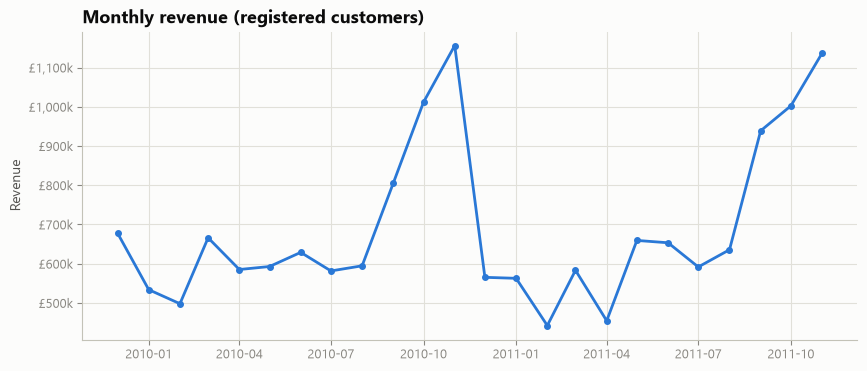

invoice_date
2010-11-01    £1,155,978
2011-11-01    £1,136,534
2010-10-01    £1,011,557
Name: value, dtype: str

In [4]:
m = inv.set_index("invoice_date")["value"].resample("MS").sum().iloc[:-1]
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(m.index, m.to_numpy() / 1e3, color=plots.SERIES[0], marker="o", ms=4)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter("£{x:,.0f}k"))
ax.set(title="Monthly revenue (registered customers)", ylabel="Revenue")
plt.show()
m.sort_values(ascending=False).head(3).map("£{:,.0f}".format)

A strong **Q4 gift season** peaks in November each year. Any forecast of future customer value has to respect this seasonality, which is why the CLV notebook aligns training and test windows by calendar.

## Customers, countries and concentration

In [5]:
cust = tx.groupby("customer_id")["revenue"].sum().clip(lower=0).sort_values(ascending=False)
top = cust.cumsum() / cust.sum()
print(f"customers: {len(cust):,}")
print(f"top 1%  of customers -> {top.iloc[int(len(cust) * 0.01)]:.0%} of net revenue")
print(f"top 20% of customers -> {top.iloc[int(len(cust) * 0.20)]:.0%} of net revenue")
country = tx.groupby("country")["revenue"].sum().sort_values(ascending=False)
(country / country.sum()).head(6).map("{:.1%}".format).to_frame("revenue share")

customers: 5,875
top 1%  of customers -> 31% of net revenue
top 20% of customers -> 77% of net revenue


,revenue share
country,
United Kingdom,83.5%
EIRE,3.5%
Netherlands,3.3%
Germany,2.3%
France,1.8%
Australia,1.0%


Revenue is highly concentrated, roughly a Pareto pattern. The UK dominates, followed by a handful of EU markets. This concentration is the reason segmentation pays off: a small set of customers deserves very different treatment from the long tail.

## Returns

In [6]:
ret = tx[tx["is_return"]]
print(f"returned value = {metrics['data']['return_value_share']:.1%} of purchases")
print(
    f"customers with at least one return: {ret['customer_id'].nunique() / tx['customer_id'].nunique():.0%}"
)

returned value = 4.2% of purchases
customers with at least one return: 42%


## Cohort retention

Each row is the month a customer first appeared. Cells show the share of that cohort that purchased again *k* months later.

> ⚠️ The **2009-12 cohort is left-censored**: data starts in December 2009, so it contains every *existing* customer, not just new ones. That is why its retention looks so high.

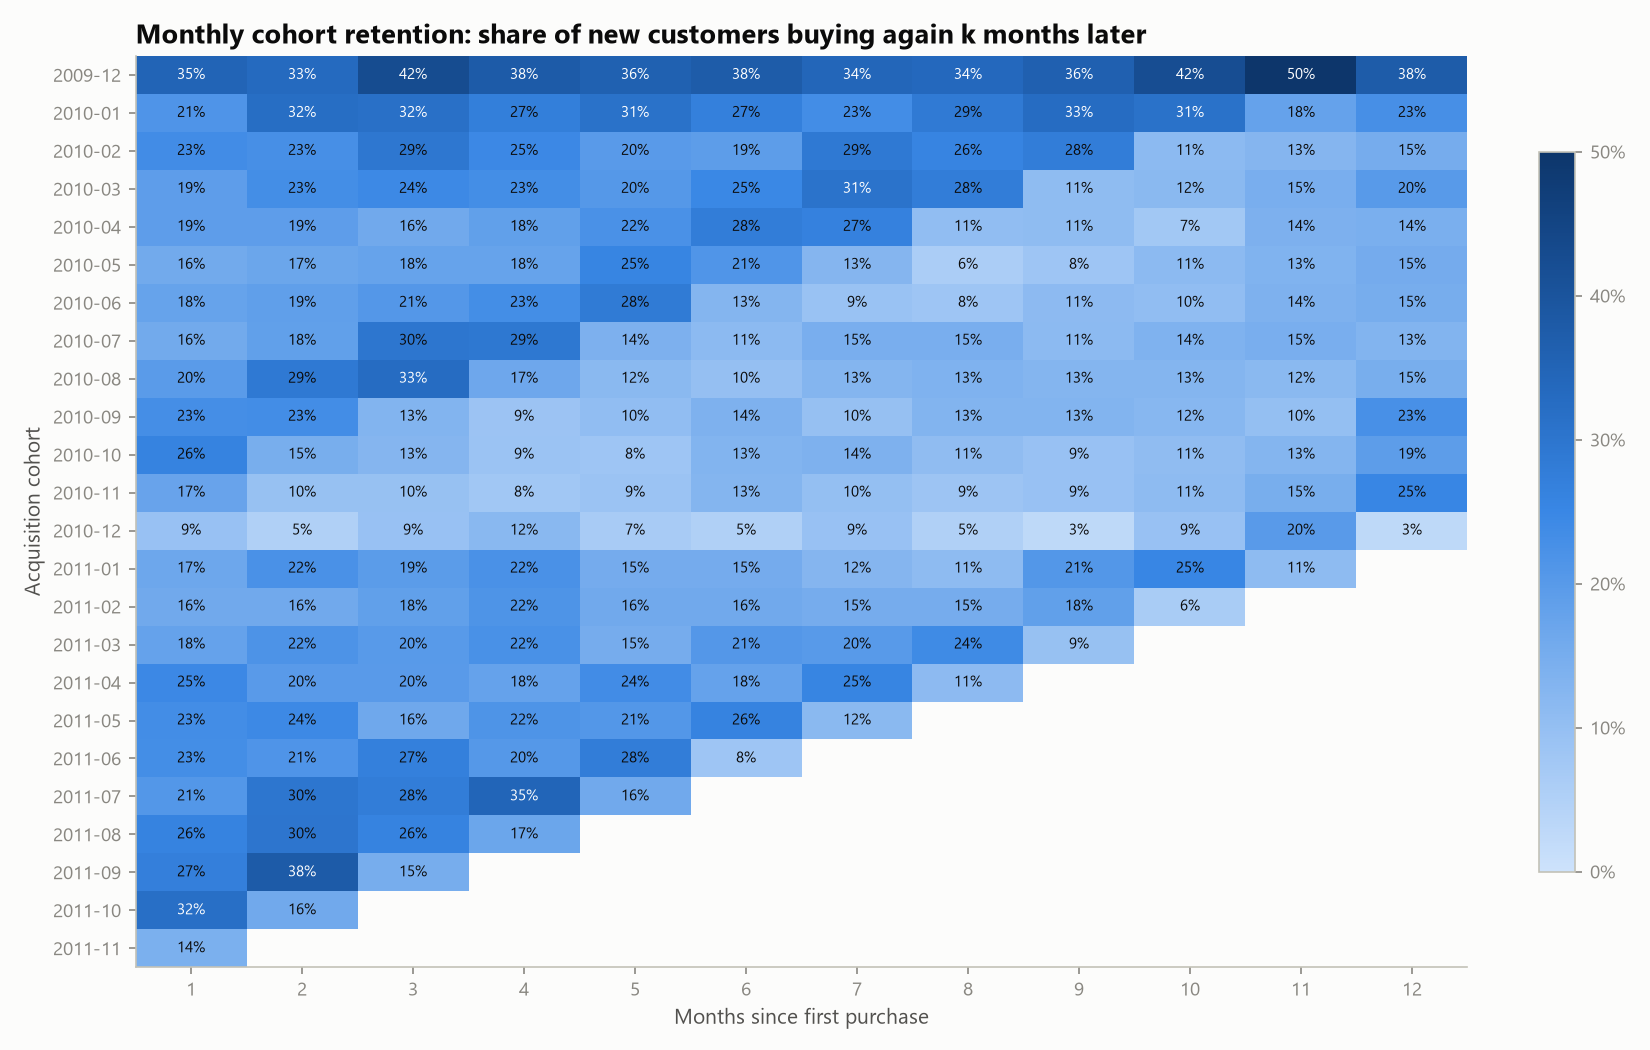

genuine new cohorts - mean month-1 retention: 20.4%, month-3: 20.7%
December 2010 cohort month-1 retention: 9.2%


In [7]:
from retail_clv import cohorts

ret = cohorts.retention_matrix(inv)
plots.cohort_heatmap(ret, "reports/figures/cohort_retention.png")
from IPython.display import Image

display(Image("reports/figures/cohort_retention.png"))
genuine = ret.loc[ret.index != "2009-12"]
print(
    f"genuine new cohorts - mean month-1 retention: {genuine[1].mean():.1%}, month-3: {genuine[3].mean():.1%}"
)
print(f"December 2010 cohort month-1 retention: {ret.loc['2010-12', 1]:.1%}")

**Takeaways**

1. Only about **1 in 5 new customers buys again the following month**, so the second purchase is the key conversion event.
2. Customers acquired in **December 2010** retain worst. They are most likely one-off Christmas gift buyers, so judging acquisition campaigns on December cohorts would understate their long-run value.
3. The customer base is a mix of a loyal, high-value wholesale core and a long tail of occasional buyers. Notebook 02 segments it.